# 05 · Os sensores são varridos ao mesmo tempo?  🔴 *difícil*

No notebook 02 vimos **quem** aparece em vários sensores. Agora: **quando**. Se o mesmo IP chega a dois sensores
com **segundos** de diferença, provavelmente é **uma única varredura** passando pelos dois. Se a diferença é de
horas ou dias, são visitas independentes.

**Perguntas deste notebook**

1. Qual a distribuição do intervalo **Δt** entre a chegada de uma origem a dois sensores?
2. Quanto dessa "simultaneidade" é **acaso**? (modelo nulo)
3. Existe uma **ordem** preferida de varredura entre os sensores?
4. Quanto um **erro de relógio** atrapalha?
5. Quantas varreduras percorrem **todos** os sensores, e com que **velocidade**?

**Por que é difícil:** é preciso definir bem o que se mede (primeira chegada? por dia?), construir um modelo nulo
honesto e desconfiar de efeitos de agregação e de relógio.

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# A pasta raiz da série (onde estão os .py). Funciona tanto na raiz quanto em solucoes/.
RAIZ = os.path.abspath("..") if os.path.basename(os.getcwd()) == "solucoes" else os.getcwd()
sys.path.insert(0, RAIZ)
import holoscope_io as hio
import holoscope_ana as ha
ha.estilo()

# >>> Para usar os DADOS REAIS, troque só esta linha pela pasta dos parquet <<<
PASTA = os.path.join(RAIZ, "dados_sinteticos")
if not os.path.isdir(PASTA):   # primeira vez: gera os dados fictícios (~20 s)
    import subprocess
    subprocess.run([sys.executable, os.path.join(RAIZ, "gerar_sintetico_real.py"), "--saida", PASTA], check=True)

In [2]:
df = hio.carregar_holoscope(PASTA, extras=("asn",))
df = df[~hio.flags_texto(df["tcp_flags"]).isin(["SA", "R", "RA"])]    # só varredura
df = ha.adicionar_entidades(df)
SENS = sorted(df["sensor"].unique())
T0 = df["ts"].min().floor("D")
print(f"{len(df):,} pacotes de varredura; período começa em {T0}")

83 arquivos | 6 sensores (worker) | 2026-09-01 a 2026-09-14 | 2,024,894 pacotes | 67 MB na memória
origens reservadas/privadas descartadas: 35,000
1,908,199 pacotes de varredura; período começa em 2026-09-01 00:00:00+00:00


## 1. O que exatamente medimos?

Para cada **entidade** (IP) e cada **sensor**, guardamos o instante da **primeira** chegada. Mas um IP que varre
os sensores em **vários dias** teria só o primeiro dia contado. Por isso usamos a primeira chegada **em cada dia**:
a unidade de análise é o par **(entidade, dia)**.

Para um par de sensores (A, B), $\Delta t = t_B - t_A$. Se $|\Delta t|$ é pequeno, as chegadas foram "simultâneas".

In [3]:
first = ha.primeira_vez(df, "ent_ip", por_dia=True)        # índice (IP, dia) x sensor
seg = first.apply(lambda c: (c - T0).dt.total_seconds())    # segundos desde T0 (mais fácil de manipular)
print(first.shape, "→ (entidade, dia) x sensor")
seg.head()

(83342, 6) → (entidade, dia) x sensor


sensor                               azure-worker-00  ifes-worker-00  polimi-worker-00  polimi-worker-01  polito-worker-00  ufes-worker-00
ent_ip    dia                                                                                                                             
202178595 2026-09-08 00:00:00+00:00              NaN             NaN               NaN               NaN     680719.897878             NaN
202179474 2026-09-03 00:00:00+00:00              NaN             NaN      2.429155e+05               NaN               NaN             NaN
          2026-09-09 00:00:00+00:00              NaN             NaN      7.651557e+05               NaN               NaN             NaN
          2026-09-13 00:00:00+00:00              NaN             NaN      1.109104e+06               NaN               NaN             NaN
202179570 2026-09-09 00:00:00+00:00              NaN             NaN               NaN      771073.65206               NaN             NaN

In [4]:
D = ha.delta_pares(seg)
D["abs"] = D["dt_s"].abs()
print(f"{len(D):,} pares (entidade-dia, sensor A, sensor B)")
limiares = {"< 1 min": 60, "< 10 min": 600, "< 1 h": 3600, "< 6 h": 6 * 3600}
pd.Series({k: (D["abs"] < v).mean() for k, v in limiares.items()}, name="fração dos pares").map("{:.1%}".format)

198,337 pares (entidade-dia, sensor A, sensor B)


< 1 min     30.7%
< 10 min    56.3%
< 1 h       65.3%
< 6 h       89.9%
Name: fração dos pares, dtype: str

## 2. Comparando com o acaso

Uma fração de pares com |Δt| < 10 min é **muito** ou **pouco**? Depende: se os sensores recebem tráfego o dia
todo, por puro acaso alguns pares cairão perto.

**Modelo nulo:** dentro de cada dia e de cada sensor, **embaralhamos** os instantes entre as entidades. Isso
mantém o perfil horário de cada sensor e quantas entidades ele vê por dia, mas **quebra** a ligação "esta entidade
chegou aqui e lá". Repetimos algumas vezes para ter uma média.

In [5]:
def nulo_mesmo_dia(seg, seed=0):
    """Embaralha, dentro de cada DIA e de cada SENSOR, os instantes entre as entidades."""
    rng = np.random.default_rng(seed)
    out = seg.copy()
    for _, bloco in seg.groupby(level="dia"):
        for c in seg.columns:
            v = bloco[c].values.copy()
            ok = ~np.isnan(v)
            v[ok] = rng.permutation(v[ok])
            out.loc[bloco.index, c] = v
    return out

nulos = [ha.delta_pares(nulo_mesmo_dia(seg, k)) for k in range(5)]
for N in nulos:
    N["abs"] = N["dt_s"].abs()
tab = pd.DataFrame({"real": {k: (D["abs"] < v).mean() for k, v in limiares.items()},
                    "nulo (média)": {k: np.mean([(N["abs"] < v).mean() for N in nulos]) for k, v in limiares.items()}})
tab["real ÷ nulo"] = tab["real"] / tab["nulo (média)"]
tab.style.format({"real": "{:.1%}", "nulo (média)": "{:.1%}", "real ÷ nulo": "{:.1f}×"})

,real,nulo (média),real ÷ nulo
< 1 min,30.7%,0.2%,201.3×
< 10 min,56.3%,1.4%,40.0×
< 1 h,65.3%,8.3%,7.9×
< 6 h,89.9%,44.9%,2.0×


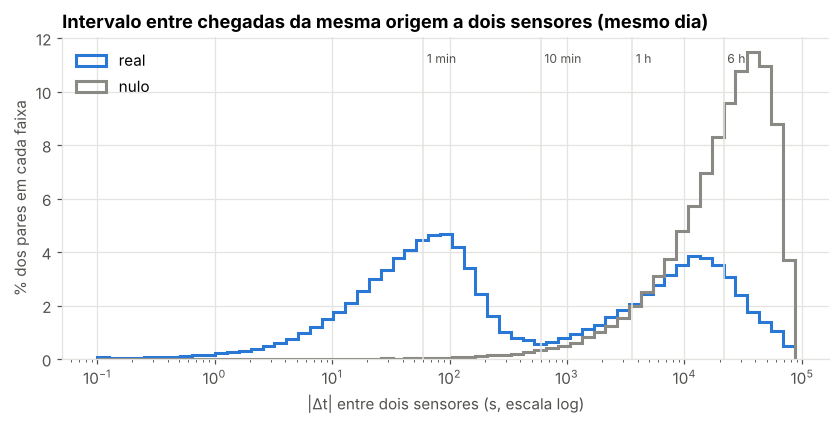

In [6]:
bins = np.logspace(-1, np.log10(86400), 60)
fig, ax = plt.subplots(figsize=(9, 3.8))
for dados, nome, cor in [(D["abs"], "real", ha.PALETA[0]), (nulos[0]["abs"], "nulo", ha.CINZA)]:
    v = dados.clip(lower=0.1)
    ax.hist(v, bins=bins, weights=np.full(len(v), 100 / len(v)), histtype="step", lw=2, color=cor, label=nome)
ax.set_xscale("log")
for v, t in [(60, "1 min"), (600, "10 min"), (3600, "1 h"), (21600, "6 h")]:
    ax.axvline(v, color=ha.GRADE, lw=1); ax.text(v, ax.get_ylim()[1] * 0.92, " " + t, fontsize=8, color=ha.TEXTO2)
ax.set_xlabel("|Δt| entre dois sensores (s, escala log)"); ax.set_ylabel("% dos pares em cada faixa")
ax.set_title("Intervalo entre chegadas da mesma origem a dois sensores (mesmo dia)"); ax.legend(loc="upper left")
plt.show()

**Leitura:** a curva real tem um **excesso** em intervalos curtos (segundos a poucos minutos) que o nulo não tem:
são as varreduras rápidas que passam por vários sensores de uma vez. Há também um segundo "morro" em horas —
varreduras **lentas** que levam horas para ir de um sensor a outro — mas esse segundo morro se **mistura** com o
nulo, que se concentra em horas (é o que se espera se duas chegadas no mesmo dia fossem independentes).
Ou seja: a simultaneidade em **minutos** é inequívoca; em **horas**, é difícil separar do acaso.

> ⚠️ **Armadilha:** o nulo **depende de escolhas**. Embaralhar no período inteiro (em vez de dentro do dia) daria
> Δt de vários dias e faria o real parecer ainda mais "simultâneo". Sempre descreva qual nulo usou.

### ✏️ TODO 1 — E no nível /24?

Repita a análise para o nível **/24** (`"ent_24"`): calcule a fração de pares com |Δt| < 10 min no dado **real** e
num **nulo** (1 repetição basta). Guarde em `resp_1 = (real_24, nulo_24)` e compare com o nível IP.
Por que a razão real/nulo muda? (Pense: a "primeira chegada de uma /24" é a mais cedo entre vários IPs diferentes.)

<details><summary><b>Dica</b> (clique)</summary>

`f24 = ha.primeira_vez(df, "ent_24", por_dia=True)`, depois converta para segundos como fizemos com `seg`.

</details>

In [7]:
resp_1 = None   # TODO

In [8]:
# Verificação (não precisa mexer)
if resp_1 is None:
    print("⏳ TODO 1 ainda não resolvido")
else:
    assert all(0 < x < 1 for x in resp_1)
    print("✅ TODO 1 ok — /24 real", f"{resp_1[0]:.1%}", "| nulo", f"{resp_1[1]:.1%}")

⏳ TODO 1 ainda não resolvido


## 3. Existe uma ordem de varredura?

Muitas ferramentas percorrem o espaço de endereços numa ordem (às vezes embaralhada, às vezes não). Se os sensores
estão em blocos diferentes, uma varredura sequencial chegaria **sempre** primeiro a uns e depois a outros.

**Matriz de precedência:** entre os pares com |Δt| < 1 h, a fração em que o sensor da **linha** foi visitado
**antes** do sensor da **coluna**. 0,5 = sem ordem preferida.

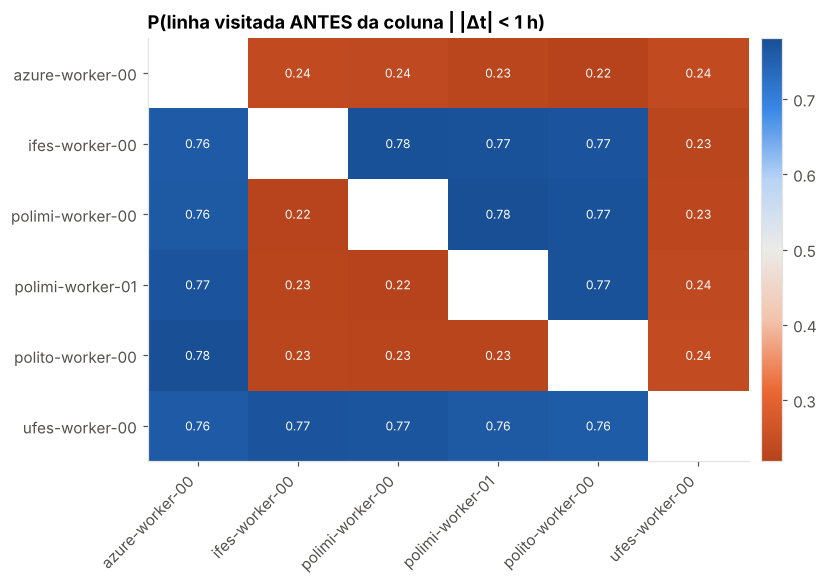

In [9]:
def precedencia(D, janela=3600):
    perto = D[D["abs"] < janela]
    M = pd.DataFrame(np.nan, index=SENS, columns=SENS)
    for (a, b), g in perto.groupby(["a", "b"]):
        p = (g["dt_s"] > 0).mean()          # dt = t_b - t_a > 0  →  a veio antes de b
        M.loc[a, b], M.loc[b, a] = p, 1 - p
    return M

PREC = precedencia(D)
fig, ax = plt.subplots(figsize=(7.5, 5))
ha.heatmap(PREC, ax=ax, centro=0.5, fmt="{:.2f}", titulo="P(linha visitada ANTES da coluna | |Δt| < 1 h)")
plt.show()

**Leitura:** valores longe de 0,5 indicam ordem preferida. Se você conseguir **ordenar** os sensores de modo que
toda a parte acima da diagonal fique azul (> 0,5), essa é a ordem "típica" das varreduras.

ordem sugerida (quem costuma vir primeiro → último):
ufes-worker-00  →  ifes-worker-00  →  polimi-worker-00  →  polimi-worker-01  →  polito-worker-00  →  azure-worker-00


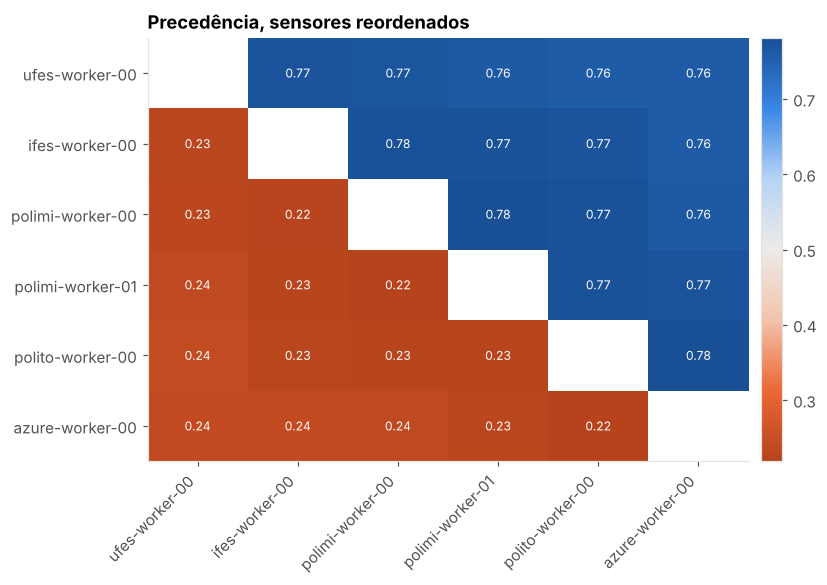

In [10]:
ordem = PREC.mean(axis=1).sort_values(ascending=False).index.tolist()
print("ordem sugerida (quem costuma vir primeiro → último):")
print("  →  ".join(ordem))
fig, ax = plt.subplots(figsize=(7.5, 5))
ha.heatmap(PREC.loc[ordem, ordem], ax=ax, centro=0.5, fmt="{:.2f}", titulo="Precedência, sensores reordenados")
plt.show()

### ✏️ TODO 2 — As ordens completas mais comuns

Para as (entidade, dia) vistas em **todos** os sensores, ordene os sensores pelo instante de chegada e forme
a sequência (ex.: `"ufes → ifes → ..."`). Guarde em `resp_2` as **5 sequências mais comuns** (`Series` com
contagens). Que fração das entidades-dia segue a sequência mais comum? Com 6 sensores há 720 ordens possíveis:
isso é muito mais que o acaso (1/720)?

<details><summary><b>Dica</b> (clique)</summary>

`completos = seg.dropna()`; para cada linha, `" → ".join(linha.sort_values().index)`. Use `.apply(..., axis=1)`.
Para encurtar os nomes: `s.replace("-worker-", "")`.

</details>

In [11]:
resp_2 = None   # TODO

In [12]:
# Verificação (não precisa mexer)
if resp_2 is None:
    print("⏳ TODO 2 ainda não resolvido")
else:
    assert len(resp_2) == 5 and resp_2.is_monotonic_decreasing
    assert resp_2.index[0].count("→") == len(SENS) - 1
    print("✅ TODO 2 ok")

⏳ TODO 2 ainda não resolvido


## 4. E se um relógio estiver errado?

Cada sensor carimba o tempo com o **seu** relógio. Se um deles estiver adiantado 2 minutos, todas as conclusões de
ordem envolvendo esse sensor ficam distorcidas — **justamente para as varreduras rápidas**, que são as mais
interessantes. Por isso o limiar de "simultâneo" deve ser **bem maior** que o erro esperado dos relógios
(sincronizados por NTP, costumam errar milissegundos; sem NTP, podem errar minutos).

### ✏️ TODO 3 — Simular um relógio adiantado

Some **+120 s** a todos os instantes do sensor que aparece **em 2º lugar** na ordem sugerida, recalcule os pares e
a matriz de precedência, e guarde em `resp_3` a **nova** matriz. Desenhe a **diferença** (nova − original).
Quais pares mudaram mais? A mudança seria a mesma com uma janela de 6 h em vez de 1 h?

<details><summary><b>Dica</b> (clique)</summary>

`seg2 = seg.copy(); seg2[ordem[1]] += 120`; depois `D2 = ha.delta_pares(seg2)`, `D2["abs"] = D2["dt_s"].abs()`
e `precedencia(D2)`.

</details>

In [13]:
resp_3 = None   # TODO

In [14]:
# Verificação (não precisa mexer)
if resp_3 is None:
    print("⏳ TODO 3 ainda não resolvido")
else:
    dif = (resp_3 - PREC).abs()
    assert dif.loc[ordem[1]].max() > dif.drop(index=ordem[1], columns=ordem[1]).max().max(), \
        "a linha do sensor alterado deveria mudar mais que as outras"
    print("✅ TODO 3 ok — maior mudança:", f"{dif.max().max():.2f}")

⏳ TODO 3 ainda não resolvido


## 5. Velocidade das varreduras completas

Para as entidades-dia vistas em todos os sensores, o **tempo total** entre o primeiro e o último sensor diz se foi
uma varredura **rápida** (segundos/minutos) ou **lenta** (horas).

### ✏️ TODO 4 — Rápidas × lentas

Calcule, para cada entidade-dia completa (`seg.dropna()`), a **duração** = último − primeiro instante (s).
Desenhe a CCDF da duração em escala log no eixo x. Guarde em `resp_4` a fração de varreduras completas com
duração **menor que 5 minutos**. A distribuição é **bimodal** (dois grupos)?

<details><summary><b>Dica</b> (clique)</summary>

`dur = completos.max(axis=1) - completos.min(axis=1)`; `x, y = ha.ccdf(dur)`; `ax.semilogx(x, y)`.

</details>

In [15]:
resp_4 = None   # TODO

In [16]:
# Verificação (não precisa mexer)
if resp_4 is None:
    print("⏳ TODO 4 ainda não resolvido")
else:
    assert 0 < resp_4 < 1
    print("✅ TODO 4 ok")

⏳ TODO 4 ainda não resolvido


## Resumo

* Defina com cuidado a unidade: **(entidade, dia)** e **primeira chegada** em cada sensor.
* Compare sempre com um **modelo nulo** — e diga qual nulo usou.
* A **matriz de precedência** revela ordens de varredura; reordenar os sensores ajuda a enxergá-las.
* **Erros de relógio** distorcem justamente as conclusões sobre varreduras rápidas.
* Varreduras completas se dividem em **rápidas** e **lentas**.

## Desafios (sem solução)

1. **Período inteiro × mesmo dia.** Refaça o histograma de |Δt| usando `ha.primeira_vez(df, "ent_ip")` (sem
   `por_dia`). O que aparece na cauda? Por quê?
2. **Rápidas por ferramenta.** Carregue `extras=("fingerprint",)`, classifique com as regras do notebook 04 e
   compare a duração das varreduras completas de ZMap × Masscan × pilhas de SO.
3. **Campanhas por porta.** Para cada (porta, hora), conte em quantos sensores houve **IPs novos** naquela porta.
   Liste as (porta, hora) vistas em ≥ 5 sensores. São as mesmas origens ou origens diferentes?
4. **Estimar o erro de relógio.** Se uma ferramenta rápida sempre visita A e B com Δt ≈ 5 s, um desvio sistemático
   na mediana de Δt entre pares pode denunciar um relógio errado. Proponha um método e teste com o relógio
   adiantado do TODO 3: você consegue recuperar os 120 s?